# DM2026 Lab 1 — Environment test

Run this notebook **after** `uv sync` (or `pip install -r requirements.txt`) in the repo root.

1. Create `config/.env` from `config/.env.example` and add at least one API key (Groq and/or Gemini).
2. Select kernel **Python (dm2026-lab1)** (or run via `uv run jupyter lab`).
3. Run all cells top to bottom.

**Before the main lab repo is out:** run this in **DM2026-Lab1-Announcement**.  
**After DM2026-Lab1-Exercise is released:** run it again from that repo’s root after `uv sync` there.

In [1]:
import sys

version = sys.version_info
print(f"Python {version.major}.{version.minor}.{version.micro}")
if version.major != 3 or version.minor != 11:
    print(
        "WARNING: This course targets Python 3.11.x. "
        "Use Python 3.11.x in this project's virtual environment (see README)."
    )
else:
    print("OK: Python 3.11.x")

Python 3.11.17
OK: Python 3.11.x


In [2]:
# Core Lab 1 stack + agentic dependencies
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn
import PAMI
import umap
import ipywidgets as widgets
from dotenv import load_dotenv
import langgraph
import langchain_core
import langchain_google_genai
import langchain_groq
import jupyterlab_widgets
import widgetsnbextension
import psutil
import cryptography
import pytest
import kaleido


print(
    "OK: core + agentic imports (pandas, numpy, nltk, matplotlib, seaborn, plotly, "
    "sklearn, PAMI, umap, ipywidgets, dotenv, langgraph, langchain, psutil, "
    "cryptography, pytest, kaleido, jupyterlab_widgets, widgetsnbextension)"
)

OK: core + agentic imports (pandas, numpy, nltk, matplotlib, seaborn, plotly, sklearn, PAMI, umap, ipywidgets, dotenv, langgraph, langchain, psutil, cryptography, pytest, kaleido, jupyterlab_widgets, widgetsnbextension)


In [3]:
import importlib.metadata as _metadata

_EXPECTED_WIDGET_VERSIONS = {
    "ipywidgets": "7.8.1",
    "jupyterlab_widgets": "1.1.11",
    "widgetsnbextension": "3.6.10",
}

print("Widget package versions:")
_widget_mismatch = False
for _pkg, _expected in _EXPECTED_WIDGET_VERSIONS.items():
    try:
        _installed = _metadata.version(_pkg)
    except _metadata.PackageNotFoundError:
        _installed = None
    _ok = _installed == _expected
    _widget_mismatch = _widget_mismatch or not _ok
    print(f"  {_pkg}: installed={_installed!r} expected={_expected!r} -> {'OK' if _ok else 'MISMATCH'}")

if _widget_mismatch:
    print(
        "WARNING: at least one widget package version does not match what this lab "
        "pins. This will not show up as an import error anywhere, but it has already "
        "caused the real agentic chat widget to render broken on a real machine. "
        "Re-run `uv sync` (or `pip install -r requirements.txt`) in this exact "
        "environment/kernel before continuing, then restart the kernel."
    )
else:
    print("OK: widget package versions match what this course pins.")


Widget package versions:
  ipywidgets: installed='7.8.1' expected='7.8.1' -> OK
  jupyterlab_widgets: installed='1.1.11' expected='1.1.11' -> OK
  widgetsnbextension: installed='3.6.10' expected='3.6.10' -> OK
OK: widget package versions match what this course pins.


In [4]:
from sklearn.datasets import fetch_20newsgroups

nltk.download("punkt", quiet=True)
categories = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]
twenty_train = fetch_20newsgroups(
    subset="train", categories=categories, shuffle=True, random_state=42
)
print(f"OK: fetch_20newsgroups — {len(twenty_train.data)} documents")

OK: fetch_20newsgroups — 2257 documents


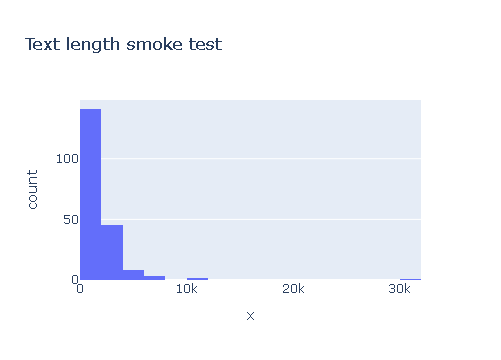

C:\Users\Angie\AppData\Local\Temp\ipykernel_17568\2969783247.py:4: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




OK: plotly + kaleido static export


In [5]:
fig = px.histogram(x=[len(t) for t in twenty_train.data[:200]], nbins=30, title="Text length smoke test")
fig.show()
try:
    fig.write_image("_test_env_plotly.png", engine="kaleido")
    import os

    os.remove("_test_env_plotly.png")
    print("OK: plotly + kaleido static export")
except Exception as exc:
    print(f"Note: kaleido export skipped ({exc}). Interactive Plotly still OK.")

In [6]:
import os
from pathlib import Path

ENV_PATH = Path("config/.env")


def _is_placeholder(value: str) -> bool:
    v = value.strip().strip('"').strip("'")
    return v.lower().startswith("your-") and v.lower().endswith("-api-key")


def _keys_for(prefix: str) -> list[str]:
    numbered = []
    for i in range(1, 11):
        val = os.getenv(f"{prefix}_{i}")
        if val and not _is_placeholder(val):
            numbered.append(val)
    if numbered:
        return numbered
    single = os.getenv(prefix)
    if single and not _is_placeholder(single):
        return [single]
    return []


if ENV_PATH.is_file():
    load_dotenv(dotenv_path=ENV_PATH)
    print(f"Loaded {ENV_PATH}")
else:
    print(f"WARNING: {ENV_PATH} not found. Copy config/.env.example to config/.env and add keys.")

groq_keys = _keys_for("GROQ_API_KEY")
google_keys = _keys_for("GOOGLE_API_KEY")
print(f"Groq configured: {bool(groq_keys)} ({len(groq_keys)} key(s), values hidden)")
print(f"Gemini configured: {bool(google_keys)} ({len(google_keys)} key(s), values hidden)")
if not groq_keys and not google_keys:
    print("ERROR: Set at least GROQ_API_KEY or GOOGLE_API_KEY in config/.env for API tests below.")

Loaded config\.env
Groq configured: True (1 key(s), values hidden)
Gemini configured: True (1 key(s), values hidden)


In [7]:
if groq_keys:
    from langchain_groq import ChatGroq

    llm = ChatGroq(
        model="openai/gpt-oss-120b",
        groq_api_key=groq_keys[0],
        temperature=0,
        request_timeout=60,
        max_retries=1,
    )
    reply = llm.invoke("Reply with exactly: OK").content
    print(f"Groq API OK — model replied: {reply[:80]!r}")
else:
    print("Skipped Groq test (no GROQ_API_KEY in config/.env).")

Groq API OK — model replied: 'OK'


In [8]:
if google_keys:
    from langchain_google_genai import ChatGoogleGenerativeAI

    llm = ChatGoogleGenerativeAI(
        model="gemini-3.6-flash",
        google_api_key=google_keys[0],
        temperature=0,
        timeout=60,
        max_retries=1,
    )
    reply = llm.invoke("Reply with exactly: OK").content
    print(f"Gemini API OK - model replied: {reply[:80]!r}")
else:
    print("Skipped Gemini test (no GOOGLE_API_KEY in config/.env).")

C:\DataMining\DM2026Labs\DM2026-Lab1-Exercise\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning:

Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


GoogleAPIError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [9]:
from IPython.display import display

_test_output = widgets.Output(
    layout=widgets.Layout(border="1px solid #ccc", height="150px", overflow_y="auto", flex="0 0 auto", width="100%")
)
_test_input_row = widgets.HBox(
    [
        widgets.Text(placeholder="(layout test only, not a real chat)", layout={"width": "80%"}),
        widgets.Button(description="Send", button_style="primary"),
    ],
    layout=widgets.Layout(flex="0 0 auto", width="100%", align_items="center"),
)
display(widgets.VBox([_test_output, _test_input_row], layout=widgets.Layout(width="100%")))
with _test_output:
    for _i in range(30):
        print(f"sample chat line {_i}")

print(
    "Check the box above: it should be a small, BORDERED, SCROLLING box holding the "
    "'sample chat line' text, with the text field and blue Send button sitting in "
    "their OWN row directly BELOW it -- not overlapping or mixed in with the text. "
    "If the Send row is missing, floating in the wrong place, or overlapping the "
    "text, that's the same bug the real agentic chat has hit before on our lab's test -- see the "
    "widget-version check above, re-run uv sync / pip install, and restart the "
    "kernel and the notebook server (not just the kernel) before re-running this."
)


Check the box above: it should be a small, BORDERED, SCROLLING box holding the 'sample chat line' text, with the text field and blue Send button sitting in their OWN row directly BELOW it -- not overlapping or mixed in with the text. If the Send row is missing, floating in the wrong place, or overlapping the text, that's the same bug the real agentic chat has hit before on our lab's test -- see the widget-version check above, re-run uv sync / pip install, and restart the kernel and the notebook server (not just the kernel) before re-running this.


## Checklist

- [ ] Python 3.11.x
- [ ] All import and 20-newsgroups cells passed
- [ ] Widget package versions all say OK (no MISMATCH)
- [ ] At least one LLM API test passed
- [ ] The scrolling test box renders correctly: bordered, scrollable, with the text
      field and Send button in their own row below it, not overlapping the text
      (local Jupyter / VS Code)

If everything passes here, you are ready for **`DM2026-Lab1-Master.ipynb`** and the subsequent agentic notebooks once Part B (main repo) is released.